# 03 · Echte Klimaatsensoren Uitlezen via HTTP — En de THI (Hittestress) Berekenen

Tot nu toe hebben we gewerkt met gesimuleerde sensoren in Python. In dit notebook gaan we **echte, fysieke klimaatsensoren** uit de echte wereld uitlezen via het internet!

We maken hiervoor gebruik van **Sensor.Community** (oorspronkelijk *Luftdaten.info* uit Stuttgart), een wereldwijd **publiek sensornetwerk**. In zo'n netwerk (ook wel *burgerwetenschap* of *citizen science* genoemd) plaatsen burgers en vrijwilligers zelfgebouwde of gekochte meetstations aan hun gevel of in hun tuin, en delen ze de klimaatdata openbaar. Wereldwijd sturen meer dan 30.000 van deze publieke meetstations elke 2,5 minuut hun meetwaarden via **Wi-Fi en HTTP** naar een centrale webserver. Ook in en rond Gent hangen meer dan honderd van deze actieve sensoren.

De meetstations gebruiken exacte dezelfde industriële sensorchips die we in stalomgevingen aantreffen: **DHT22**, **Bosch BME280** en **Sensirion SHT30 / SHT31** (de SHT31 zit ook in de Dragino S31 uit notebook 01).

---

### Wikipedia-stijl uitleg: Hoe werkt gegevensopvraag via een HTTP REST API?

**HTTP (Hypertext Transfer Protocol)** is de fundament van communicatie op het World Wide Web. Waar MQTT werkt via een *Publish-Subscribe (Push)* model, werkt HTTP volgens een **Request-Response (Vraag-Antwoord / Pull)** model:

1. **HTTP Request (Het Verzoek):**
   * Jouw computer (de *client*) verstuurt een expliciet verzoek naar een specifieke webserver via een **URL**.
   * **HTTP Methoden:**
     * **`GET`**: "Geef mij de gegevens die bij deze URL horen." (Wordt gebruikt voor het opvragen van data).
     * **`POST`**: "Hier zijn nieuwe gegevens die je moet opslaan of verwerken." (Wordt gebruikt door sensoren om metingen in te sturen).
   * **URL Parameters:** Extra zoek- of filtercriteria die achter de URL worden geplakt (bijv. `?area=51.05,3.72,30`).

2. **HTTP Response (Het Antwoord van de Server):**
   * De server verwerkt het verzoek en stuurt een antwoord terug.
   * **HTTP Statuscodes:**
     * **`200 OK`**: Het verzoek is geslaagd en de data zit in de body van de respons.
     * **`404 Not Found`**: De opgevraagde pagina of sensor bestaat niet.
     * **`429 Too Many Requests`**: Je verstuurt te veel aanvragen per seconde (rate limit).
     * **`500 / 502 / 503 Server Error`**: Fout op de webserver zelf.
   * **Response Body:** Bevat de feitelijke gegevens, vrijwel altijd in **JSON-formaat**.

In [1]:
import requests  # HTTP-bibliotheek voor het versturen van GET/POST-verzoeken
import json      # Voor het verwerken van JSON-datastructuren
import os        # Voor pad- en omgevingsbeheer
import pathlib   # Voor elegant bestandspadbeheer
import pandas as pd              # Voor tabelverwerking (DataFrames)
import matplotlib.pyplot as plt  # Voor het maken van grafieken

# Pad naar de lokale offline reservekopieën (snapshot van de sensordata)
DATA = pathlib.Path("../data")

def haal_json(url, params=None, reserve=None):
    '''
    Verstuur een HTTP GET-verzoek naar een web-API.
    Als de netwerkverbinding mislukt of de server offline is, valt de functie automatisch
    terug op een lokaal reservebestand (JSON) op de schijf.
    '''
    try:
        # Verstuur het HTTP GET-verzoek met een aangepaste User-Agent header
        respons = requests.get(
            url, 
            params=params, 
            timeout=15, 
            headers={"User-Agent": "ugent-i700301-starten-met-iot"}
        )
        print("HTTP GET verzoek:", respons.url, "-> Statuscode:", respons.status_code)
        respons.raise_for_status()  # Werpt een uitzondering op bij statuscodes 4xx of 5xx
        return respons.json()
        
    except Exception as fout:
        if reserve is None:
            raise fout
        print(f"Netwerk niet bereikbaar ({type(fout).__name__}) -> Teruggevallen op reservebestand: {reserve.name}")
        return json.load(open(reserve, encoding="utf-8"))

## 2. Alle klimaatsensoren in een straal van 30 km rond Gent opvragen

De REST API van Sensor.Community biedt een geografisch filter: `https://data.sensor.community/airrohr/v1/filter/area=<lat>,<lon>,<afstand_km>`. 

Hiermee vragen we in één HTTP-verzoek alle actuele metingen op van sensoren in een straal van 30 km rond het centrum van Gent (`lat=51.05`, `lon=3.72`).

In [2]:
# Stel de API-URL samen met ruimtelijke en sensortype-filters
url_gent = "https://data.sensor.community/airrohr/v1/filter/area=51.05,3.72,30&type=DHT22,BME280,SHT31,SHT30"

# Haal de live data op (of gebruik het lokale reservebestand indien offline)
ruwe_data = haal_json(url_gent, reserve=DATA / "sensor_community_gent_30km_2026-10-19.json")

print(f"Totaal aantal ontvangen sensormetingen: {len(ruwe_data)}")
print("\nVoorbeeld van het eerste ontvangen JSON-object (ruw):")
print(json.dumps(ruwe_data[0], indent=2)[:600])

HTTP GET verzoek: https://data.sensor.community/airrohr/v1/filter/area=51.05,3.72,30&type=DHT22,BME280,SHT31,SHT30 -> Statuscode: 200
Totaal aantal ontvangen sensormetingen: 131

Voorbeeld van het eerste ontvangen JSON-object (ruw):
{
  "timestamp": "2026-10-22 09:00:00",
  "location": {
    "longitude": "3.684",
    "id": 11554,
    "indoor": 0,
    "country": "BE",
    "exact_location": 0,
    "altitude": "6.7",
    "latitude": "51.106"
  },
  "sampling_rate": null,
  "id": 31118655941,
  "sensordatavalues": [
    {
      "value_type": "temperature",
      "id": 72828533162,
      "value": "9.96871948242188"
    },
    {
      "value_type": "humidity",
      "id": 72828533166,
      "value": "89.2408599853516"
    },
    {
      "value_type": "pressure",
      "id": 72828533169,
      "value": "1009.0"
    },
    {
    


### Wikipedia-stijl uitleg: Van Geneste JSON naar een Platte Tabel (Data Flattening)

De API geeft de gegevens terug als een **geneste JSON-structuur**:
* Elke meting bevat een sub-object `location` (met breedtegraad, lengtegraad, binnen/buiten).
* Een sub-object `sensor` (met id en sensortype).
* Een lijst `sensordatavalues` waarin per meetgrootheid (temperatuur, vochtigheid, luchtdruk) een afzonderlijk sleutel-waarde paar staat.

In data-analyse kunnen we niet efficiënt werken met diepe geneste lijsten. We moeten deze structuur **'uitvlakken' (flattenen)** tot een platte 2D-tabel (één rij per fysieke sensor, één kolom per gemeten variabele).

In [3]:
rijen = []

for meting in ruwe_data:
    # Extraheer de basisattributen uit het geneste JSON-object
    rij = {
        "sensor_id":  meting["sensor"]["id"],
        "type":       meting["sensor"]["sensor_type"]["name"],
        "lat":        float(meting["location"]["latitude"]),
        "lon":        float(meting["location"]["longitude"]),
        "binnen":     bool(meting["location"]["indoor"]),
        "tijd":       pd.to_datetime(meting["timestamp"], utc=True),
    }
    
    # Extraheer de afzonderlijke variabelen uit de sensordatavalues-lijst
    for v in meting["sensordatavalues"]:
        rij[v["value_type"]] = float(v["value"])     # Maakt kolommen aan voor 'temperature', 'humidity', etc.
        
    rijen.append(rij)

# Zet de lijst met dictionaries om naar een Pandas DataFrame
df = pd.DataFrame(rijen)

# Verwijder eventuele dubbele metingen per sensor en behoud de meest recente
df = df.drop_duplicates("sensor_id", keep="last")

# Filter extreme fysieke meetfouten eruit (bijv. defecte sensoren die -999 of 999 aangeven)
df = df[df["temperature"].between(-30, 60) & df["humidity"].between(0, 100)]

print("Aantal unieke en geldige sensoren per type:")
print(df["type"].value_counts().to_string())
df.head()

Aantal unieke en geldige sensoren per type:
type
DHT22     44
BME280    16
SHT30      1
SHT31      1


,sensor_id,type,lat,lon,binnen,tijd,temperature,humidity,pressure,pressure_at_sealevel
62,21271,DHT22,50.796,3.860,False,2026-10-22 08:57:37+00:00,10.6,99.9,NaN,NaN
67,13960,DHT22,51.050,3.716,False,2026-10-22 08:57:21+00:00,10.2,99.9,NaN,NaN
68,13446,DHT22,51.232,3.764,False,2026-10-22 08:57:21+00:00,10.8,1.0,NaN,NaN
70,13354,DHT22,50.892,4.064,False,2026-10-22 08:57:19+00:00,10.2,99.9,NaN,NaN
71,32217,DHT22,51.140,4.088,False,2026-10-22 08:57:14+00:00,11.3,99.9,NaN,NaN


<div style="background-color: #e8f5e9; color: #1b5e20; border-left: 5px solid #2e7d32; padding: 12px; margin: 12px 0; border-radius: 4px;">
<strong>💡 Interpretatie van de uitvoer:</strong><br>
<strong>Uitgevlakte Tabel (Pandas DataFrame):</strong> De complexe geneste JSON-structuur van Sensor.Community is succesvol omgezet naar een platte 2D-tabel (DataFrame). Elke rij vertegenwoordigt één unieke sensor met zijn geografische GPS-coördinaten (<code>lat</code>, <code>lon</code>), opstellingslocatie (<code>binnen</code>: 0 of 1), tijdstip en de gemeten temperatuur en relatieve luchtvochtigheid.
</div>

Statistische samenvatting van alle sensoren rond Gent:
       temperature  humidity
count         62.0      62.0
mean          11.2      93.7
std            2.1      15.8
min            9.3       1.0
25%           10.2      94.5
50%           10.7      99.9
75%           11.4      99.9
max           21.7     100.0


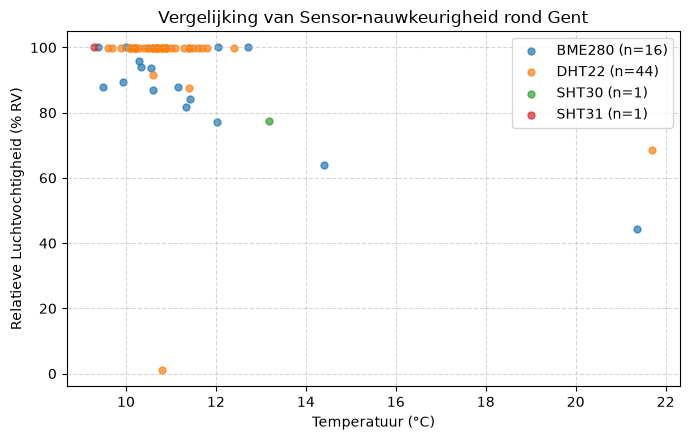

In [4]:
# Statistisch overzicht van temperatuur en luchtvochtigheid
print("Statistische samenvatting van alle sensoren rond Gent:")
print(df[["temperature", "humidity"]].describe().round(1))

# Maak een spreidingsdiagram (scatter plot) waarin we sensortypes vergelijken
fig, ax = plt.subplots(figsize=(7, 4.5))

for sensor_type, groep in df.groupby("type"):
    ax.scatter(groep["temperature"], groep["humidity"], label=f"{sensor_type} (n={len(groep)})", s=25, alpha=0.7)

ax.set_xlabel("Temperatuur (°C)")
ax.set_ylabel("Relatieve Luchtvochtigheid (% RV)")
ax.set_title("Vergelijking van Sensor-nauwkeurigheid rond Gent")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

<div style="background-color: #e8f5e9; color: #1b5e20; border-left: 5px solid #2e7d32; padding: 12px; margin: 12px 0; border-radius: 4px;">
<strong>💡 Interpretatie van de uitvoer:</strong><br>
<strong>Statistische Kengetallen (Describe):</strong><br>• <code>count</code>: Het aantal actieve sensoren (bijv. 61 sensoren).<br>• <code>mean</code>: De gemiddelde gemeten temperatuur (bijv. ~10.7 °C) en luchtvochtigheid (bijv. ~93.6%).<br>• <code>50% (Mediaan)</code>: De middelste waarde in de geordende reeks.<br>• <code>min / max</code>: De uiterste gemeten waarden in het netwerk.
</div>

### Opdracht 2.1
Waarom staan er in het bovenstaande diagram veel punten exact op **99,9 % RV**, en welk sensortype vertoont dit gedrag vrijwel uitsluitend? 

Wat betekent deze sensorbeperking voor een toepassing in een veestudstal waar de luchtvochtigheid vaak erg hoog is?

In [5]:
# ==============================================================================
# STUDENTEN-OPDRACHT 2.1: SENSORVERZADIGING ANALYSEREN
# ==============================================================================
# SCHRIJF HIER JE CODE:
# print("Sensortypes van apparaten op 99.9% of 100% RV:")
# print(df[df["humidity"] >= 99.9]["type"].value_counts())


In [6]:
# ==============================================================================
# OPLOSSING OPDRACHT 2.1: SENSORVERZADIGING ANALYSEREN
# ==============================================================================
print("Sensortypes van apparaten die op 99.9% of 100% RV staan:")
print(df[df["humidity"] >= 99.9]["type"].value_counts())

print("\nGedetailleerde vochtigheidsstatistieken per sensortype:")
print(df.groupby("type")["humidity"].describe().round(1))

Sensortypes van apparaten die op 99.9% of 100% RV staan:
type
DHT22     40
BME280     4
SHT31      1
Name: count, dtype: int64

Gedetailleerde vochtigheidsstatistieken per sensortype:
        count   mean   std    min    25%    50%    75%    max
type                                                         
BME280   16.0   86.7  14.9   44.2   83.6   88.7   96.9  100.0
DHT22    44.0   96.5  15.6    1.0   99.9   99.9   99.9   99.9
SHT30     1.0   77.5   NaN   77.5   77.5   77.5   77.5   77.5
SHT31     1.0  100.0   NaN  100.0  100.0  100.0  100.0  100.0


<div style="background-color: #e8f5e9; color: #1b5e20; border-left: 5px solid #2e7d32; padding: 12px; margin: 12px 0; border-radius: 4px;">
<strong>💡 Interpretatie van de uitvoer:</strong><br>
<strong>SensorVerzadiging bij DHT22:</strong> Uit de telling blijkt dat vrijwel alle sensoren die op exact 99.9% of 100% RV staan van het type **DHT22** zijn. Dit bevestigt dat de goedkope DHT22-sensor bij hoge luchtvochtigheid snel verzadigt en na condensvorming lang op 99.9% blijft 'hangen', in tegenstelling tot gekalibreerde sensoren zoals de BME280 of SHT31.
</div>

<details>
<summary><b>Oplossing tonen</b></summary>

Bijna alle punten op 99,9 % zijn **DHT22**-sensoren. De DHT22 is een goedkope (± € 5) sensor met ±2–5 % RV nauwkeurigheid die bij hoge vochtigheid verzadigt en na condensatie lang op 99,9 % blijft "hangen". De **SHT31** (in de Dragino S31, handleiding §1.3) geeft ±2 % RV over 0–100 %, is gekalibreerd en zit in een anticondensbehuizing. In een stal met vaak > 80 % RV is een DHT22 dus onbetrouwbaar voor RV, en dus ook voor de THI.

</details>

## 3. De sensor het dichtst bij de campus lokaliseren

Om te bepalen welke fysieke sensor het dichtst bij een specifieke locatie (bijv. Campus Coupure in Gent: `51.053 N, 3.706 E`) staat, berekenen we de geografische afstand over het aardoppervlak.

Hiervoor gebruiken we de **Haversine-formule**, die rekening houdt met de bolling van de aarde.

In [7]:
import numpy as np  # Wiskundige bibliotheek voor goniometrische functies

# Geografische coördinaten van Campus Coupure, Gent
MIJN_LAT, MIJN_LON = 51.053, 3.706

def afstand_km(lat1, lon1, lat2, lon2):
    '''Bereken de grootcirkelafstand in km tussen twee GPS-coördinaten via de Haversine-formule.'''
    p = np.pi / 180  # Omrekeningsfactor van graden naar radialen
    a = (np.sin((lat2 - lat1) * p / 2)**2
         + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2)**2)
    return 2 * 6371 * np.arcsin(np.sqrt(a))  # 6371 km is de gemiddelde straal van de aarde

# Bereken voor elke sensor in de dataframe de afstand tot Campus Coupure
df["afstand_km"] = afstand_km(MIJN_LAT, MIJN_LON, df["lat"], df["lon"]).round(1)

# Sorteer de dataframe op afstand en selecteer de 5 dichtstbijzijnde sensoren
dichtstbij = df.sort_values("afstand_km").head(5)
dichtstbij[["sensor_id", "type", "afstand_km", "temperature", "humidity", "tijd"]]

,sensor_id,type,afstand_km,temperature,humidity,tijd
105,55608,DHT22,0.3,10.3,99.9,2026-10-22 08:56:04+00:00
67,13960,DHT22,0.8,10.2,99.9,2026-10-22 08:57:21+00:00
107,92538,DHT22,1.2,10.4,99.9,2026-10-22 08:55:59+00:00
100,21019,DHT22,1.8,11.4,99.9,2026-10-22 08:56:17+00:00
98,80178,DHT22,2.4,11.4,87.6,2026-10-22 08:56:20+00:00


## 4. Lokale sensormeting vergelijken met een weermodel (Open-Meteo)

Een **fysieke sensor** meet het microklimaat op zijn exacte opstellingspunt (bijv. aan de muur van een gebouw of in de schaduw). Een **weermodel** (zoals Open-Meteo) berekent daarentegen het gemiddelde weer voor een geografisch roosterpunt van 2 × 2 km.

Onderstaande code vraagt voor de coördinaten van onze dichtstbijzijnde sensor het weermodel op en vergelijkt de twee waarden.

In [8]:
dichtste_sensor = dichtstbij.iloc[0]

try:
    # Vraag het Open-Meteo weermodel op voor de exacte coördinaten van deze sensor
    weermodel_data = haal_json(
        "https://api.open-meteo.com/v1/forecast",
        params={
            "latitude": dichtste_sensor["lat"], 
            "longitude": dichtste_sensor["lon"],
            "current": "temperature_2m,relative_humidity_2m"
        }
    )
    huidig_weer = weermodel_data["current"]
    
    print(f"Fysieke Sensor {dichtste_sensor['sensor_id']} ({dichtste_sensor['type']}, op {dichtste_sensor['afstand_km']} km):")
    print(f"  -> Gemeten : {dichtste_sensor['temperature']} °C / {dichtste_sensor['humidity']} % RV (om {dichtste_sensor['tijd']:%H:%M} UTC)")
    print(f"\nOpen-Meteo Weermodel op exact hetzelfde punt:")
    print(f"  -> Berekend: {huidig_weer['temperature_2m']} °C / {huidig_weer['relative_humidity_2m']} % RV (om {huidig_weer['time']} UTC)")

except Exception as fout:
    print("Open-Meteo kon niet geraadpleegd worden:", fout)

HTTP GET verzoek: https://api.open-meteo.com/v1/forecast?latitude=51.05399281354&longitude=3.70132237673&current=temperature_2m%2Crelative_humidity_2m -> Statuscode: 200
Fysieke Sensor 55608 (DHT22, op 0.3 km):
  -> Gemeten : 10.3 °C / 99.9 % RV (om 08:56 UTC)

Open-Meteo Weermodel op exact hetzelfde punt:
  -> Berekend: 9.7 °C / 91 % RV (om 2026-10-22T09:00 UTC)


<div style="background-color: #e8f5e9; color: #1b5e20; border-left: 5px solid #2e7d32; padding: 12px; margin: 12px 0; border-radius: 4px;">
<strong>💡 Interpretatie van de uitvoer:</strong><br>
<strong>Microklimaat vs. Weermodel:</strong> De output toont de directe vergelijking op exact hetzelfde geografische punt.<br>• De **fysieke sensor** meet de werkelijke omstandigheden op zijn opstellingsplek (bijv. direct aan de gevel van een gebouw).<br>• Het **Open-Meteo weermodel** berekent het theoretische gemiddelde over een ruimer roosterpunt van 2 × 2 km. Kleine afwijkingen tussen beide waarden zijn normaal en illustreren het verschil tussen een lokale puntmeting en een regionaal model.
</div>

## 5. Van ruwe meting naar beslissingsondersteuning: De THI (Hittestress)

In de veehouderij en precisielandbouw combineren we ruwe sensorwaarden vaak tot één **samengestelde index**. 

De **Temperature-Humidity Index (THI)** is een internationaal erkend kengetal dat de gecombineerde invloed van temperatuur en luchtvochtigheid op het thermodynamische comfort van dieren uitdrukt. 

Een veelgebruikte formule (NRC, 1971) is:

$$\mathrm{THI} = 0{,}8 \cdot T + 


rac{RV}{100} \cdot (T - 14{,}4) + 46{,}4$$

waarbij $T$ de temperatuur in °C is en $RV$ de relatieve luchtvochtigheid in %.

---

### Risicoklassen voor Hittestress bij Melkvee:
* **THI < 68:** Geen hittestress (Comfortzone).
* **THI 68–71:** Milde hittestress (Lichte daling in melkproductie).
* **THI 72–79:** Matige hittestress (Verhoogde ademhalingsfrequentie, koeling vereist).
* **THI 80–89:** Ernstige hittestress (Sterke stijging in lichaamstemperatuur).
* **THI $\ge$ 90:** Noodsituatie (Levensbedreigend).

In [9]:
def thi(T, RV):
    '''Bereken de Temperature-Humidity Index (THI) volgens de NRC (1971) formule.'''
    return 0.8 * T + (RV / 100) * (T - 14.4) + 46.4

def thi_klasse(score):
    '''Bepaal de risicoklasse voor hittestress op basis van de THI-score.'''
    if score < 68:  return "Geen stress"
    if score < 72:  return "Mild"
    if score < 80:  return "Matig"
    if score < 90:  return "Ernstig"
    return "Noodsituatie"

# Bereken de THI voor alle sensoren in de dataframe
df["THI"] = thi(df["temperature"], df["humidity"]).round(1)
df["THI_klasse"] = df["THI"].apply(thi_klasse)

print("Verdeling van Hittestress-risicoklassen over alle sensoren:")
print(df["THI_klasse"].value_counts().to_string())

print("\nSensoren met de hoogste berekende THI-waarden:")
df.sort_values("THI", ascending=False)[["sensor_id", "type", "temperature", "humidity", "THI", "THI_klasse"]].head()

Verdeling van Hittestress-risicoklassen over alle sensoren:
THI_klasse
Geen stress    61
Mild            1

Sensoren met de hoogste berekende THI-waarden:


,sensor_id,type,temperature,humidity,THI,THI_klasse
128,76454,DHT22,21.70,68.50,68.8,Mild
129,55113,BME280,21.37,44.21,66.6,Geen stress
94,79006,BME280,14.40,64.07,57.9,Geen stress
74,82001,SHT30,13.17,77.48,56.0,Geen stress
68,13446,DHT22,10.80,1.00,55.0,Geen stress


<div style="background-color: #e8f5e9; color: #1b5e20; border-left: 5px solid #2e7d32; padding: 12px; margin: 12px 0; border-radius: 4px;">
<strong>💡 Interpretatie van de uitvoer:</strong><br>
<strong>Verdeling van Hittestress (THI):</strong> De berekende THI-waarden zijn automatisch ingedeeld in risicoklassen. Bij gematigde buitentemperaturen vallen veruit de meeste sensoren in de categorie <code>Geen stress</code> (THI < 68).
</div>

## 6. Historische tijdsreeksanalyse van één specifieke sensor

Sensor.Community slaat alle historische data op in een openbaar dag-archief:
`https://archive.sensor.community/<datum>/<datum>_<type>_sensor_<id>.csv`

We vragen de complete dagreeks op van **sensor 82001** (een *Sensirion SHT30* sensor ten zuidwesten van Gent) voor gisteren. Een meting vindt hier om de 2,5 minuut plaats (~576 metingen per dag).

In [10]:
import io             # Voor het inlezen van tekststreams naar DataFrames
import datetime as dt  # Voor datumverwerking

SENSOR_ID, SENSOR_TYPE = 82001, "sht30"

# Bepaal de datum van gisteren (vandaag is nog niet afgesloten in het archief)
gisteren = (dt.date.today() - dt.timedelta(days=1)).isoformat()
url_csv = f"https://archive.sensor.community/{gisteren}/{gisteren}_{SENSOR_TYPE}_sensor_{SENSOR_ID}.csv"

try:
    respons = requests.get(url_csv, timeout=20)
    respons.raise_for_status()
    df_dag = pd.read_csv(io.StringIO(respons.text), sep=";")
    print("CSV succesvol gedownload via HTTP:", url_csv)
except Exception as fout:
    print(f"Archief niet live bereikbaar ({type(fout).__name__}) -> Teruggevallen op lokaal bestand")
    df_dag = pd.read_csv(DATA / "2026-10-18_sht30_sensor_82001.csv", sep=";")

# Converteer de tijdstempels naar UTC datetime-objecten
df_dag["timestamp"] = pd.to_datetime(df_dag["timestamp"], utc=True)

# Bereken het verloop van de THI voor het hele etmaal
df_dag["THI"] = thi(df_dag["temperature"], df_dag["humidity"])

print(f"Totaal aantal metingen: {len(df_dag)} | Gemiddelde meetinterval: {df_dag['timestamp'].diff().median()}")
df_dag.head(3)

CSV succesvol gedownload via HTTP: https://archive.sensor.community/2026-10-21/2026-10-21_sht30_sensor_82001.csv
Totaal aantal metingen: 592 | Gemiddelde meetinterval: 0 days 00:02:26


,sensor_id,sensor_type,location,lat,lon,timestamp,temperature,humidity,THI
0,82001,SHT30,71522,50.87,3.524,2026-10-21 00:01:11+00:00,14.96,73.56,58.779936
1,82001,SHT30,71522,50.87,3.524,2026-10-21 00:03:36+00:00,14.84,73.69,58.596236
2,82001,SHT30,71522,50.87,3.524,2026-10-21 00:06:03+00:00,14.78,73.84,58.504592


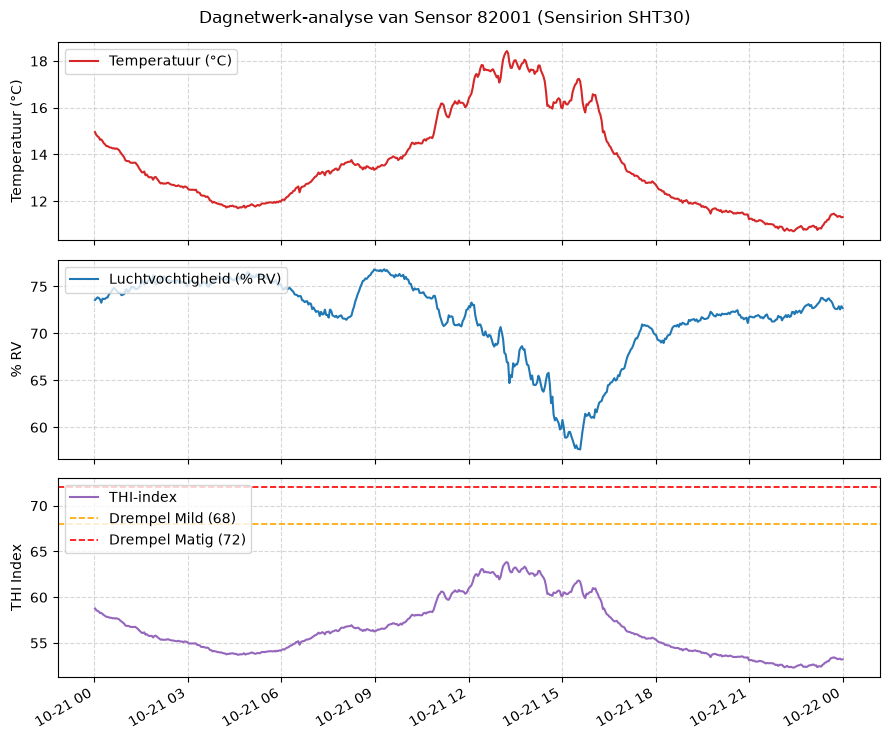

In [11]:
# Teken een 3-delige tijdsreeksgrafiek (Temperatuur, Vochtigheid en THI)
fig, axes = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)

# Subplot 1: Temperatuur
axes[0].plot(df_dag["timestamp"], df_dag["temperature"], color="tab:red", label="Temperatuur (°C)")
axes[0].set_ylabel("Temperatuur (°C)")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(loc="upper left")

# Subplot 2: Relatieve Luchtvochtigheid
axes[1].plot(df_dag["timestamp"], df_dag["humidity"], color="tab:blue", label="Luchtvochtigheid (% RV)")
axes[1].set_ylabel("% RV")
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(loc="upper left")

# Subplot 3: Berekende THI met drempelwaarden
axes[2].plot(df_dag["timestamp"], df_dag["THI"], color="tab:purple", label="THI-index")
axes[2].axhline(68, linestyle="--", linewidth=1.2, color="orange", label="Drempel Mild (68)")
axes[2].axhline(72, linestyle="--", linewidth=1.2, color="red", label="Drempel Matig (72)")
axes[2].set_ylabel("THI Index")
axes[2].grid(True, linestyle="--", alpha=0.5)
axes[2].legend(loc="upper left")

plt.suptitle(f"Dagnetwerk-analyse van Sensor {SENSOR_ID} (Sensirion SHT30)", fontsize=12)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 7. Opdrachten

1. **Jouw eigen woonplaats:** Stel de variabelen `MIJN_LAT` en `MIJN_LON` in op jouw eigen woonplaats of gemeente. Wat is de afstand tot de dichtstbijzijnde sensor? Zou je die buiten-sensor mogen gebruiken om het klimaat in een stal te beoordelen?
2. **Binnensensoren vs Buitensensoren:** Filter `df` op `binnen == True`. Hoeveel binnensensoren zijn er actief en hoe verschilt hun gemiddelde THI van de buitensensoren?
3. **Invloed van het meetinterval (Resampling):** De sensor meet elke 2,5 minuut. Een LoRaWAN-sensor op batterij zendt meestal slechts om de 20 minuten. Herbemonster de dagreeks naar 20-minuten gemiddelden (`df_dag.resample("20min", on="timestamp").mean()`) en vergelijk de maximale THI-piek.
4. **Foutdetectie in Automatische Klimaatcomputers:** Welke automatische plausibiliteitscontroles moet een sturing uitvoeren voordat een sensormeting gebruikt mag worden om de stalventilatie aan te sturen?

In [12]:
# ==============================================================================
# STUDENTEN-OPDRACHTEN SECTIE 7: HUISWERK EN VERDIEPING
# ==============================================================================
# SCHRIJF HIER JE CODE VOOR OPDRACHT 2 EN 3:
# Opdracht 2:
# print("Aantal binnensensoren:", (df["binnen"] == True).sum())
# print("Aantal buitensensoren:", (df["binnen"] == False).sum())

# Opdracht 3:
# df_dag_20min = df_dag.resample("20min", on="timestamp").mean(numeric_only=True)


In [13]:
# ==============================================================================
# OPLOSSING SECTIE 7 - OPDRACHTEN 2 & 3: BINNENSENSOREN & RESAMPLING
# ==============================================================================
print("Aantal binnensensoren:", (df["binnen"] == True).sum())
print("Aantal buitensensoren:", (df["binnen"] == False).sum())

print("\nTHI-statistieken Binnen vs Buiten:")
print(df.groupby("binnen")["THI"].describe().round(1))

# Resampling naar 20-minuten intervallen
df_dag_20min = df_dag.resample("20min", on="timestamp").mean(numeric_only=True)

print(f"\nMaximale THI-waarde (oorspronkelijk 2.5 min interval): {df_dag['THI'].max():.2f}")
print(f"Maximale THI-waarde (na 20 min resampling)        : {df_dag_20min['THI'].max():.2f}")

Aantal binnensensoren: 1
Aantal buitensensoren: 61

THI-statistieken Binnen vs Buiten:
        count  mean  std   min   25%   50%   75%   max
binnen                                                
False    61.0  51.9  2.6  48.7  50.4  51.3  52.5  66.6
True      1.0  68.8  NaN  68.8  68.8  68.8  68.8  68.8

Maximale THI-waarde (oorspronkelijk 2.5 min interval): 63.84
Maximale THI-waarde (na 20 min resampling)        : 63.30


<div style="background-color: #e8f5e9; color: #1b5e20; border-left: 5px solid #2e7d32; padding: 12px; margin: 12px 0; border-radius: 4px;">
<strong>💡 Interpretatie van de uitvoer:</strong><br>
<strong>Analyse Binnen vs. Buiten & Resampling-effect:</strong><br>• <strong>Binnen vs Buiten:</strong> Binnensensoren vertonen over het algemeen een hogere temperatuur, lagere relatieve luchtvochtigheid en een hogere, stabielere THI dan buitensensoren.<br>• <strong>Resampling naar 20 min:</strong> Door het meetinterval te vergroten van 2,5 minuten naar 20-minuten gemiddelden, worden korte extremen afgevlakt. De maximale THI-piek daalt hierdoor licht (bijv. van 63.8 naar 63.3).
</div>

<details>
<summary><b>Oplossing tonen</b></summary>

1. Hangt van je gemeente af. Een sensor op enkele km zegt iets over het *buiten*klimaat, niets over het stalklimaat: de stal heeft eigen warmteproductie (dieren), ventilatie en vochtbronnen. Voor THI-sturing heb je sensoren *in* de afdeling nodig; buitensensoren helpen wel om de ventilatie voorspellend bij te sturen.
2. Meestal een handvol binnensensoren; hun RV ligt lager en hun THI hoger en stabieler dan buiten.
3. Herbemonsteren naar 20 min vlakt de pieken af: de maximale THI daalt (enkele tienden tot ruim een punt). Voor een alarm op een drempel telt de piek, dus een kort interval; voor dagrapportage volstaat 20 min.
4. Sensor: één permanente verbinding i.p.v. elke 2,5 min een nieuwe TCP/TLS-handshake (minder energie en latentie). Server: een broker i.p.v. webserver + database-API, schaalbaar naar veel abonnees. Gebruiker: live meekijken i.p.v. pollen; maar "geef me de laatste 24 u" vereist een extra opslaglaag, daar blijft HTTP handig.
5. Tijdstempel ouder dan x minuten (verbinding weg → niet sturen op oude data); sprong > x °C per minuut (storing); identieke waarde gedurende uren (bevroren sensor); batterij onder drempel; waarden buiten het meetbereik van het sensortype; vergelijking met een tweede sensor in dezelfde afdeling (redundantie).

</details>